In [ ]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
import string
from itertools import product
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from transformers import BertForSequenceClassification, BertTokenizer
import torch
from torch.utils.data import TensorDataset, DataLoader, RandomSampler
from transformers import AdamW
import matplotlib.pyplot as plt

In [ ]:
# Carregar os dados originais
df_nomes = pd.read_csv('nomes_pessoais.csv')
df_nomes['y'] = 1

df_palavras = pd.read_csv('palavras_comuns.csv').sample(n=102561, random_state=42)
df_palavras['y'] = 0

df = pd.concat([df_nomes, df_palavras])
df.shape


(205122, 2)

In [ ]:
# Carregar o arquivo gabarito_formatado.csv
unique_words_df = pd.read_csv('gabarito_formatado.csv')

# Remover valores NaN na coluna 'palavra'
unique_words_df = unique_words_df.dropna(subset=['palavra'])

# Converter todos os valores '-1' para '0' na coluna 'y'
unique_words_df['y'] = unique_words_df['y'].replace(-1, 0)

# Separar palavras e nomes
words_df = unique_words_df[unique_words_df['y'] == 0]
names_df = unique_words_df[unique_words_df['y'] == 1]

# Samplear aleatoriamente 743 palavras
words_sample_df = words_df.sample(n=743, random_state=42)

# Concatenar as palavras sampleadas com todos os nomes
balanced_test_df = pd.concat([words_sample_df, names_df])

# Shuffle o dataframe para misturar as palavras e os nomes
balanced_test_df = balanced_test_df.sample(frac=1, random_state=42).reset_index(drop=True)

# Verificar a distribuição de rótulos no conjunto de teste balanceado
label_distribution = balanced_test_df['y'].value_counts()
print("Distribuição de rótulos no conjunto de teste balanceado:")
print(label_distribution)

balanced_test_df

Distribuição de rótulos no conjunto de teste balanceado:
y
1    743
0    743
Name: count, dtype: int64


,palavra,y
0,DAVID,1
1,STELMO,1
2,DEICHAR,0
3,AUTORIDADES,0
4,SISTEMATICAMENTE,0
...,...,...
1481,BARBALHO,1
1482,DANIEL,1
1483,KELLE,1
1484,NICOLLE,1


In [ ]:
# Carregar o modelo BERTimbau pré-treinado e o tokenizer
model_name = 'neuralmind/bert-base-portuguese-cased'
bert_model = BertForSequenceClassification.from_pretrained(model_name, num_labels=2)
tokenizer = BertTokenizer.from_pretrained(model_name)


/usr/local/lib/python3.10/dist-packages/huggingface_hub/utils/_token.py:89: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/647 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/438M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at neuralmind/bert-base-portuguese-cased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


tokenizer_config.json:   0%|          | 0.00/43.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/210k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

In [ ]:
# Função para tokenizar os dados
def tokenize_data(data):
    return tokenizer(data, padding=True, truncation=True, return_tensors='pt')

In [ ]:
# Tokenizar os dados de treino
X_train_tokens = tokenize_data(df['X'].tolist())
y_train = torch.tensor(df['y'].values)

# Tokenizar as palavras únicas para teste
X_unique_words_tokens = tokenize_data(balanced_test_df['palavra'].tolist())
y_true = torch.tensor(balanced_test_df['y'].values)

Asking to truncate to max_length but no maximum length is provided and the model has no predefined maximum length. Default to no truncation.


In [ ]:
# Criar DataLoader para o conjunto de treino
train_dataset = TensorDataset(X_train_tokens['input_ids'], X_train_tokens['attention_mask'], y_train)
train_sampler = RandomSampler(train_dataset)
train_dataloader = DataLoader(train_dataset, sampler=train_sampler, batch_size=16)

# Treinar o modelo BERTimbau
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
bert_model.to(device)
optimizer = AdamW(bert_model.parameters(), lr=2e-5)

/usr/local/lib/python3.10/dist-packages/transformers/optimization.py:588: FutureWarning: This implementation of AdamW is deprecated and will be removed in a future version. Use the PyTorch implementation torch.optim.AdamW instead, or set `no_deprecation_warning=True` to disable this warning
  warnings.warn(


In [ ]:
for epoch in range(10):  # Ajuste o número de épocas conforme necessário
    bert_model.train()
    total_loss = 0
    total_correct = 0
    total_samples = 0
    print(f'Época {epoch + 1}/10:')
    for batch_idx, batch in enumerate(train_dataloader):
        optimizer.zero_grad()
        input_ids, attention_mask, labels = batch
        input_ids = input_ids.to(device)
        attention_mask = attention_mask.to(device)
        labels = labels.to(device)
        outputs = bert_model(input_ids, attention_mask=attention_mask, labels=labels)
        loss = outputs.loss
        logits = outputs.logits
        preds = torch.argmax(logits, dim=1)
        total_correct += torch.sum(preds == labels).item()
        total_samples += len(labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

        # Log a cada 10 batches
        if (batch_idx + 1) % 10 == 0:
            avg_loss = total_loss / (batch_idx + 1)
            avg_accuracy = total_correct / total_samples
            print(f'    Batch {batch_idx + 1}/{len(train_dataloader)} - Loss: {avg_loss:.4f}, Acurácia: {avg_accuracy:.4f}')

A saída de streaming foi truncada nas últimas 5000 linhas.
    Batch 1320/12821 - Loss: 0.0376, Acurácia: 0.9872
    Batch 1330/12821 - Loss: 0.0377, Acurácia: 0.9872
    Batch 1340/12821 - Loss: 0.0378, Acurácia: 0.9870
    Batch 1350/12821 - Loss: 0.0377, Acurácia: 0.9871
    Batch 1360/12821 - Loss: 0.0375, Acurácia: 0.9872
    Batch 1370/12821 - Loss: 0.0376, Acurácia: 0.9872
    Batch 1380/12821 - Loss: 0.0378, Acurácia: 0.9871
    Batch 1390/12821 - Loss: 0.0379, Acurácia: 0.9871
    Batch 1400/12821 - Loss: 0.0380, Acurácia: 0.9870
    Batch 1410/12821 - Loss: 0.0379, Acurácia: 0.9870
    Batch 1420/12821 - Loss: 0.0379, Acurácia: 0.9870
    Batch 1430/12821 - Loss: 0.0381, Acurácia: 0.9870
    Batch 1440/12821 - Loss: 0.0379, Acurácia: 0.9871
    Batch 1450/12821 - Loss: 0.0380, Acurácia: 0.9871
    Batch 1460/12821 - Loss: 0.0378, Acurácia: 0.9872
    Batch 1470/12821 - Loss: 0.0379, Acurácia: 0.9872
    Batch 1480/12821 - Loss: 0.0381, Acurácia: 0.9871
    Batch 1490/12821 - 

In [ ]:
# Avaliar o modelo BERTimbau
bert_model.eval()
with torch.no_grad():
    input_ids = X_unique_words_tokens['input_ids'].to(device)
    attention_mask = X_unique_words_tokens['attention_mask'].to(device)
    outputs = bert_model(input_ids, attention_mask=attention_mask)
    logits = outputs.logits
    y_pred = torch.argmax(logits, dim=1).cpu().numpy()

In [ ]:
# Calcular as métricas
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)

print(f"Accuracy: {accuracy}")
print(f"Precision: {precision}")
print(f"Recall: {recall}")
print(f"F1 Score: {f1}")

Accuracy: 0.8553162853297442
Precision: 0.8492063492063492
Recall: 0.8640646029609691
F1 Score: 0.8565710473649099


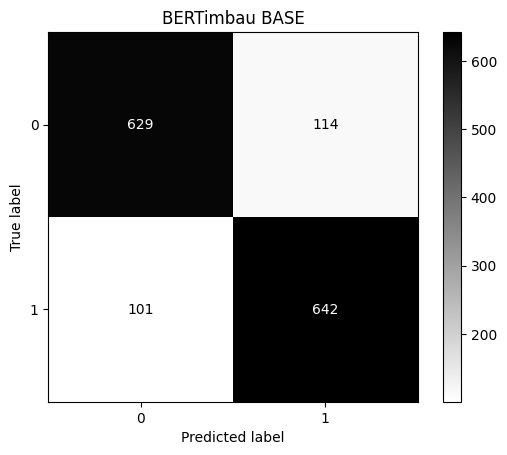

In [ ]:
# Gerar a matriz de confusão
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
disp.plot(cmap='binary')
plt.title('BERTimbau BASE')
plt.show()

In [ ]:
unique_words_df.info('y')

<class 'pandas.core.frame.DataFrame'>
Index: 5596 entries, 0 to 5596
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   palavra  5596 non-null   object
 1   y        5596 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 131.2+ KB
